# **Spring-Mass System: Inverse Inference with MDN and CRPS**

A toy inverse problem: given a measured displacement $t_1$, infer the distribution over the
spring's **mass ($m$)** and **stiffness ($k$)** that could have produced it.

$$
u(T) = u_0 \cos \left( \sqrt{\frac{k}{m}} T \right) + \frac{v_0}{\sqrt{\frac{k}{m}}} \sin \left( \sqrt{\frac{k}{m}} T \right), \qquad T = 10
$$

This is a **one-to-many** problem, many different $(m, k)$ pairs can produce the same
$t_1$, so a plain regression model isn't enough; we need a model of the full predictive
distribution.

We train **two different models** for this, a **Mixture Density Network (MDN)** and a
**CRPS-trained model**, using the exact same training loop and data split, so the two approaches
are directly comparable.

<div style="text-align: center;">
    <img src="https://raw.githubusercontent.com/TRACE-Structures/digital_twinning/main/demo/data/spring/spring.png" alt="Image" width="180">
</div>

# Setup

In [ ]:
!pip install digital_twinning


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uncertain_variables import *
import digital_twinning as dt

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

# 1. Generate data

In [2]:
def spring_solve(q_i, x0=1, v0=0, d=0, T=10):
    m = q_i[:, 0]
    k = q_i[:, 1]
    alpha = d / m
    D = (k / m) - (alpha ** 2)
    omega = np.sqrt(D)
    xt = np.exp(-alpha * T) * (x0 * np.cos(omega * T) + (v0 + alpha * x0) / omega * np.sin(omega * T))
    return xt.reshape(-1, 1)

In [3]:
P1 = Variable('m', UniformDistribution(1, 2.5))
P2 = Variable('k', UniformDistribution(0.5, 2))

Q = VariableSet()
Q.add(P1)
Q.add(P2)

num_samples = 8000
Q_i = Q.sample(num_samples, method='QMC_Halton', random_seed=1997)
Q_df = pd.DataFrame(Q_i, columns=['m','k'])
QoI_i = spring_solve(Q_i)
QoI_names = ['t_1']
QoI_df = pd.DataFrame(QoI_i, columns=QoI_names)

X = QoI_df[QoI_names].to_numpy().astype(np.float32)

# add some measurement noise
noise_std = 0.02
rng_noise = np.random.default_rng(1997)
X = X + rng_noise.normal(scale=noise_std, size=X.shape).astype(np.float32)

y = Q_df[['m','k']].to_numpy().astype(np.float32)

X.shape, y.shape

((8000, 1), (8000, 2))

In [4]:
m_grid = np.linspace(1, 2.5, 200)
k_grid = np.linspace(0.5, 2, 200)
M, K = np.meshgrid(m_grid, k_grid)

Z_solver = spring_solve(np.array([[M.reshape(-1), K.reshape(-1)]])).reshape(K.shape)
# fig = dt.plot_3Dscatter(K, M, Z_solver)

# 2. MDN model

In [7]:
layers =[{'neurons': 64, 'activation': 'gelu', 'dropout': None},         # activation ['gelu', 'relu', 'sigmoid', 'tanh', 'leakyrelu', 'softmax', 'none']
        {'neurons': 128, 'activation': 'gelu', 'dropout': None}]

model = dt.MDN(Q, QoI_names, layers, n_components=10)

c:\Users\Bence\AppData\Local\Programs\Python\Python313\Lib\site-packages\torchnaut\mdn.py:142: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\python_variable_indexing.cpp:351.)
  self.tril_template[tril_ix.tolist()] = torch.arange(tril_ix.shape[1])


In [ ]:
optimizer='adamw'
max_epoch=80
batch_size=32
lr=1e-3
weight_decay=1e-6
max_patience=50

model.train(X, y, k_fold=None, optimizer=optimizer, max_epoch=max_epoch, batch_size=batch_size, lr=lr, weight_decay=weight_decay, max_patience=max_patience, verbose=True)

----- Training started for 'MDNModel' model -----
epoch    0 | train 2.2428 | val 1.5245
epoch   20 | train 0.1749 | val 0.2152
epoch   40 | train -0.0406 | val -0.0731
epoch   60 | train -0.0887 | val -0.1867
----- Training ended for 'MDNModel' model -----


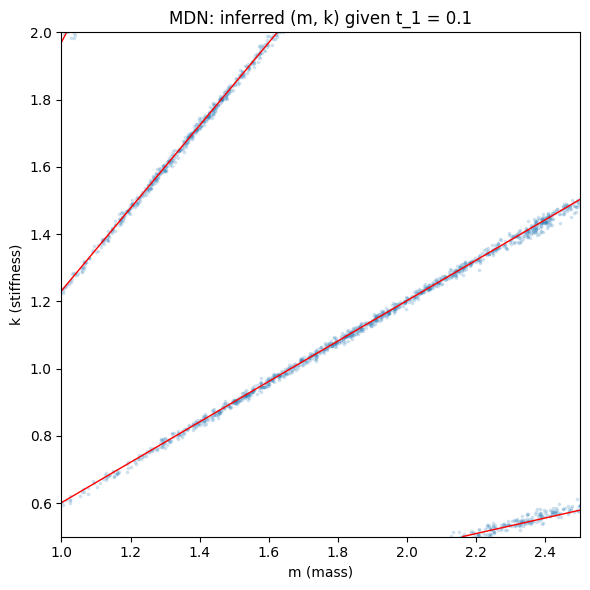

In [9]:
def plot_inference(mk_samples, y_obs, title):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(mk_samples[:, 0], mk_samples[:, 1], s=3, alpha=0.15)
    ax.contour(M, K, Z_solver, levels=[y_obs], colors='red', linewidths=1)
    ax.set_xlabel("m (mass)")
    ax.set_ylabel("k (stiffness)")
    ax.set_xlim(1, 2.5); ax.set_ylim(0.5, 2)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

y_obs = np.array([[0.1]])

mdn_samples = model.inference(y_obs)
plot_inference(mdn_samples, y_obs, f"MDN: inferred (m, k) given t_1 = {y_obs[0, 0]}")

In [11]:
map_df = model.get_MAP(mdn_samples)

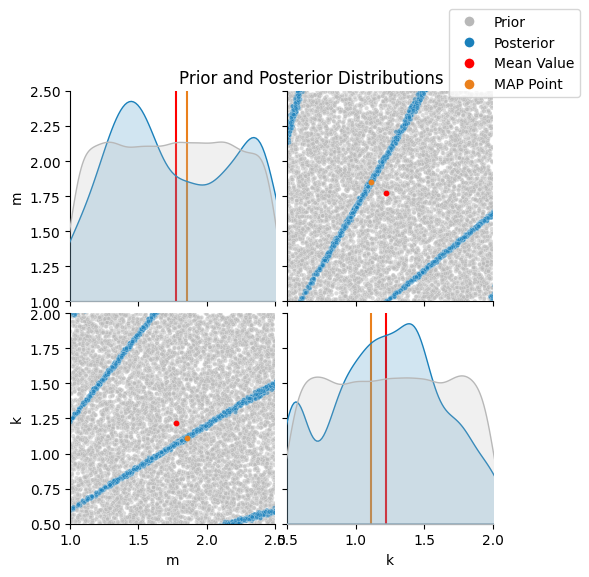

In [13]:
model.plot_posterior(y, mdn_samples, map_point=map_df)

# 3. CRPS model

In [15]:
layers =[{'neurons': 64, 'activation': 'gelu', 'dropout': None},         # activation ['gelu', 'relu', 'sigmoid', 'tanh', 'leakyrelu', 'softmax', 'none']
        {'neurons': 128, 'activation': 'gelu', 'dropout': None},
        {'neurons': 256, 'activation': 'gelu', 'dropout': None}]


model = dt.CRPS(Q, QoI_names, layers, n_epsilon=64)

optimizer='adamw'
max_epoch=200
batch_size=32
lr=1e-3
weight_decay=1e-6
max_patience=80

model.train(X, y, k_fold=None, optimizer=optimizer, max_epoch=max_epoch, batch_size=batch_size, lr=lr, weight_decay=weight_decay, max_patience=max_patience, verbose=True)

----- Training started for 'CRPSModel' model -----
epoch    0 | train 0.8792 | val 0.8213
epoch   20 | train 0.8086 | val 0.8065
epoch   40 | train 0.8047 | val 0.7969
epoch   60 | train 0.8078 | val 0.8012
epoch   80 | train 0.8041 | val 0.7958
epoch  100 | train 0.8049 | val 0.7964
epoch  120 | train 0.8036 | val 0.7973
epoch  140 | train 0.8047 | val 0.7990
Early stopping at epoch 147 (best val loss 0.7920)
----- Training ended for 'CRPSModel' model -----


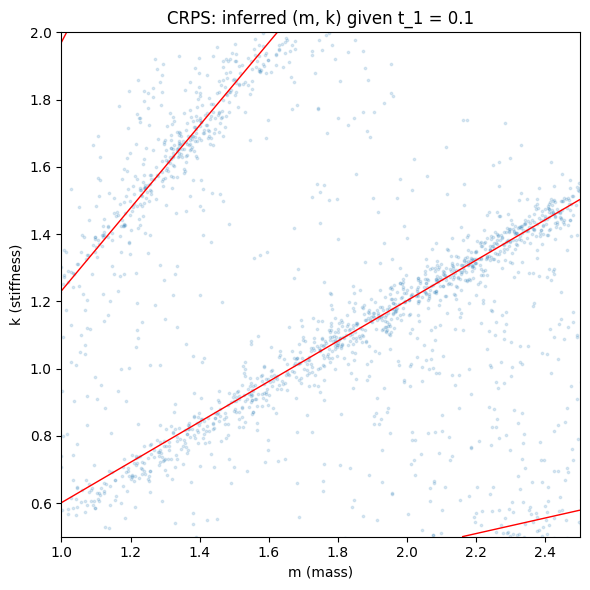

In [16]:
y_obs = np.array([[0.1]])

crps_samples = model.inference(y_obs)
plot_inference(crps_samples, y_obs, f"CRPS: inferred (m, k) given t_1 = {y_obs[0, 0]}")

In [17]:
crps_map = model.get_MAP(crps_samples)

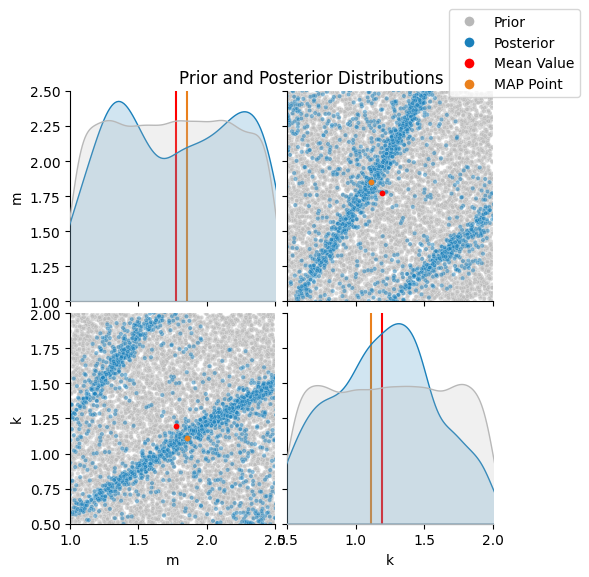

In [19]:
model.plot_posterior(y, crps_samples, map_point=map_df)